In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Sequential

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
image = np.array([
    [1,  2,  3,  4,  5],
    [6,  7,  8,  9, 10],
    [11, 12, 13, 14, 15],
    [16, 17, 18, 19, 20],
    [21, 22, 23, 24, 25]
], dtype=np.float32)

print("Image shape:", image.shape)
print(image)

Image shape: (5, 5)
[[ 1.  2.  3.  4.  5.]
 [ 6.  7.  8.  9. 10.]
 [11. 12. 13. 14. 15.]
 [16. 17. 18. 19. 20.]
 [21. 22. 23. 24. 25.]]


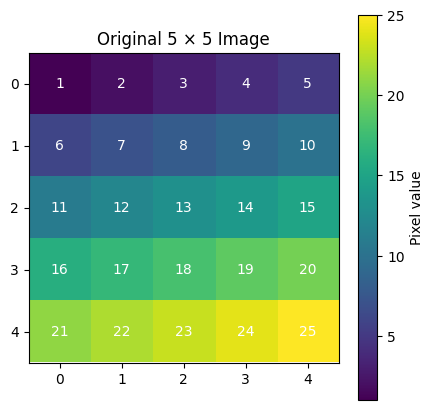

In [3]:
plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="viridis")
plt.colorbar(label="Pixel value")
plt.title("Original 5 × 5 Image")
plt.xticks(range(5))
plt.yticks(range(5))

for i in range(5):
    for j in range(5):
        plt.text(j, i, int(image[i, j]),
                 ha="center", va="center", color="white")

plt.show()

# Keras Conv2D expects image data in the format:

# (batch_size, height, width, channels)

In [4]:
image_input = image[np.newaxis, :, :, np.newaxis]

print("Input shape:", image_input.shape)

# The dimensions mean one image, height 5, width 5, and one channel.

Input shape: (1, 5, 5, 1)


<!-- Create two convolution layers
Both layers use the same kernel size and number of filters. The only difference is padding. -->

# Create two convolution layers
# Both layers use the same kernel size and number of filters. The only difference is padding.

In [8]:
valid_model = Sequential([
    layers.Input(shape=(5, 5, 1)),
    layers.Conv2D(
        filters=1,
        kernel_size=(3, 3),
        strides=1,
        padding="valid",
        use_bias=False
    )
])

same_model = Sequential([
    layers.Input(shape=(5, 5, 1)),
    layers.Conv2D(
        filters=1,
        kernel_size=(3, 3),
        strides=1,
        padding="same",
        use_bias=False
    )
])

print("Valid output shape:", valid_model.output_shape)
print("Same output shape:", same_model.output_shape)



Valid output shape: (None, 3, 3, 1)
Same output shape: (None, 5, 5, 1)


In [6]:
# our input image is 5 * 5, and your kernel is 3*3.

# When we use padding="valid", we add no extra pixels around the image. The kernel must fit completely inside the original image


# -----------------------------------------------------------------------------------------------


# Now, understand same padding
# When we use padding="same" with stride 1, Keras adds a border of zeros around the image so the kernel can also produce outputs for the original border locations.

# For a 3*3 kernel, we add one pixel of padding on each side.


# Use the same filter weights in both models

In [7]:
kernel = np.ones((3, 3, 1, 1), dtype=np.float32)

valid_model.layers[0].set_weights([kernel])
same_model.layers[0].set_weights([kernel])

print("Kernel:")
print(kernel[:, :, 0, 0])

Kernel:
[[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]


# Apply convolution

In [9]:
valid_output = valid_model.predict(image_input, verbose=0)
same_output = same_model.predict(image_input, verbose=0)

valid_map = valid_output[0, :, :, 0]
same_map = same_output[0, :, :, 0]

print("Valid feature map:\n", valid_map)
print("\nSame feature map:\n", same_map)

Valid feature map:
 [[12.75789  14.058775 15.35966 ]
 [19.262318 20.563202 21.864088]
 [25.766745 27.06763  28.368517]]

Same feature map:
 [[ 0.7264666  -1.7966957  -1.5990844  -1.4014729   2.5518894 ]
 [ 2.8688076   0.12448817  0.25051486  0.37654108  2.6207695 ]
 [ 6.4231086   0.7546207   0.88064736  1.006675    2.1347303 ]
 [ 9.977409    1.3847542   1.5107808   1.6368084   1.6486921 ]
 [ 9.780254   12.252039   12.762802   13.273567    0.35927886]]


# Compare feature maps visually

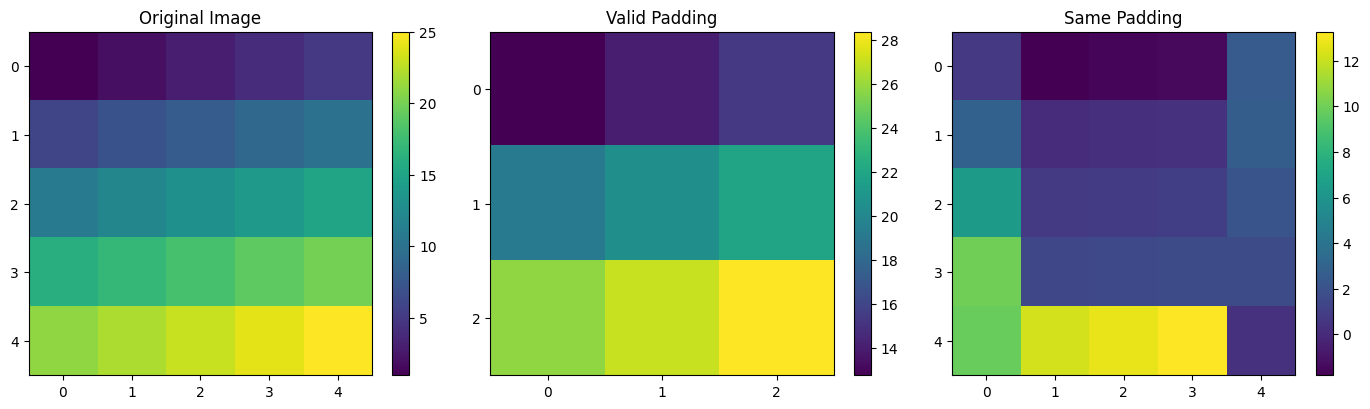

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

plots = [
    (image, "Original Image"),
    (valid_map, "Valid Padding"),
    (same_map, "Same Padding")
]

for ax, (data, title) in zip(axes, plots):
    im = ax.imshow(data, cmap="viridis")
    ax.set_title(title)
    ax.set_xticks(range(data.shape[1]))
    ax.set_yticks(range(data.shape[0]))
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

In [11]:
print("Original image size:", image.shape)
print("Valid feature map size:", valid_map.shape)
print("Same feature map size:", same_map.shape)

print("\nConclusion:")
print("Valid padding reduces spatial dimensions.")
print("Same padding preserves spatial dimensions for stride 1.")

Original image size: (5, 5)
Valid feature map size: (3, 3)
Same feature map size: (5, 5)

Conclusion:
Valid padding reduces spatial dimensions.
Same padding preserves spatial dimensions for stride 1.
